In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


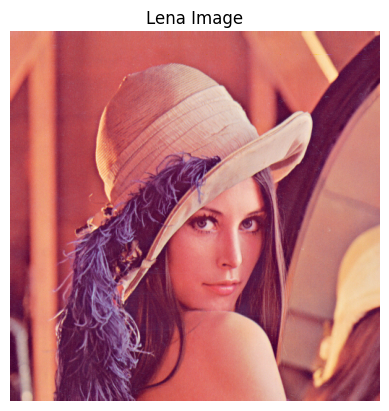

In [ ]:
import matplotlib.pyplot as plt

image_path = '/content/drive/MyDrive/Colab/images/lena.jpg'

img = cv2.imread(image_path)

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.imshow(img_rgb)
    plt.axis('off')
    plt.title('Lena Image')
    plt.show()

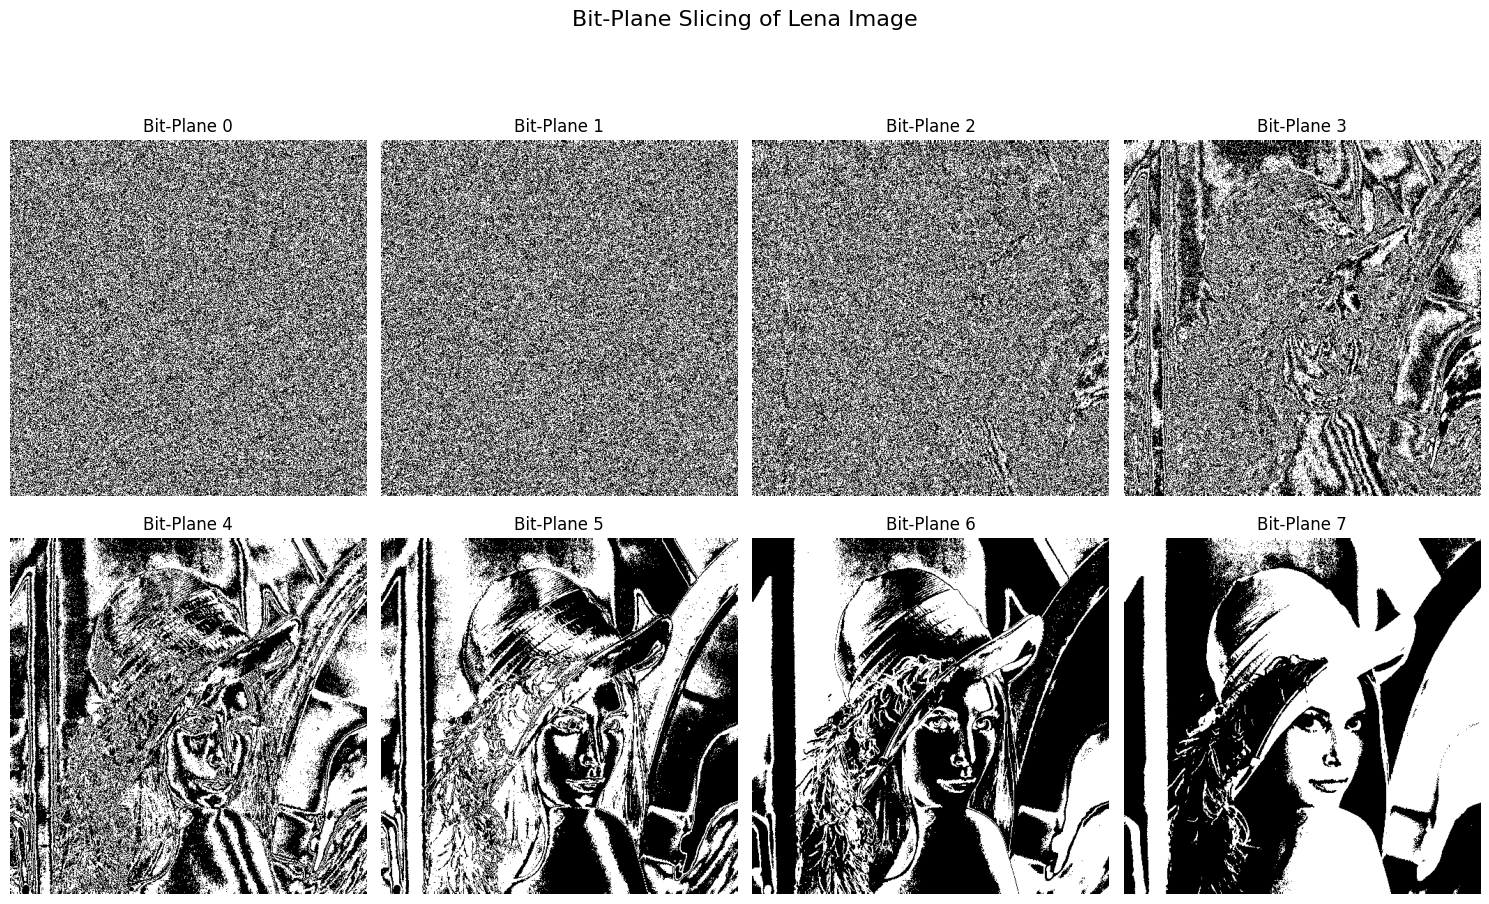

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    plt.figure(figsize=(15, 10))
    plt.suptitle('Bit-Plane Slicing of Lena Image', fontsize=16)

    for i in range(8):
        bit_plane = (gray_img & (1 << i)) * 255

        plt.subplot(2, 4, i + 1)
        plt.imshow(bit_plane, cmap='gray')
        plt.title(f'Bit-Plane {i}')
        plt.axis('off')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


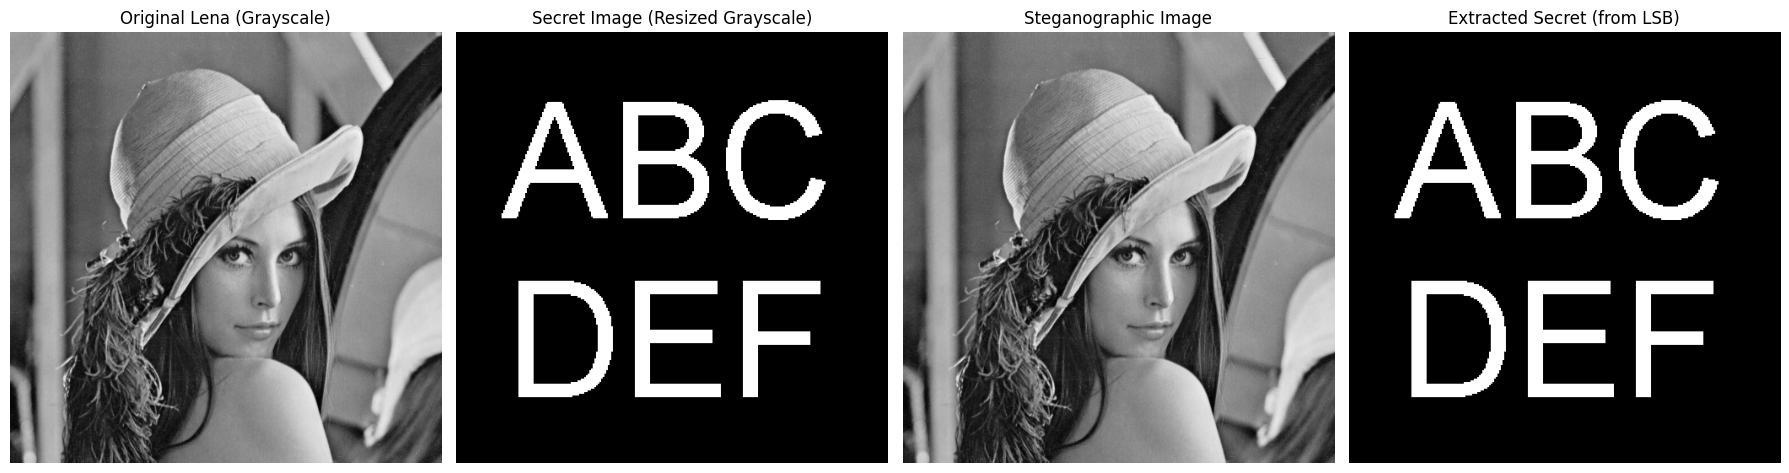

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

    secret_image_path = '/content/drive/MyDrive/Colab/images/abcdef.bmp'
    secret_img_orig = cv2.imread(secret_image_path)

        if 'gray_img' not in locals() or gray_img is None:
            gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        secret_gray = cv2.cvtColor(secret_img_orig, cv2.COLOR_BGR2GRAY)

        h, w = gray_img.shape
        secret_gray_resized = cv2.resize(secret_gray, (w, h), interpolation=cv2.INTER_AREA)

        stego_img = gray_img & 0xFE

        secret_bit_plane = (secret_gray_resized >> 7) & 1

        stego_img = stego_img | secret_bit_plane

        extracted_secret = (stego_img & 1) * 255

        plt.figure(figsize=(18, 6))

        plt.subplot(1, 4, 1)
        plt.imshow(gray_img, cmap='gray')
        plt.title('Original Lena (Grayscale)')
        plt.axis('off')

        plt.subplot(1, 4, 2)
        plt.imshow(secret_gray_resized, cmap='gray')
        plt.title('Secret Image (Resized Grayscale)')
        plt.axis('off')

        plt.subplot(1, 4, 3)
        plt.imshow(stego_img, cmap='gray')
        plt.title('Steganographic Image')
        plt.axis('off')

        plt.subplot(1, 4, 4)
        plt.imshow(extracted_secret, cmap='gray')
        plt.title('Extracted Secret (from LSB)')
        plt.axis('off')

        plt.tight_layout()
        plt.show()


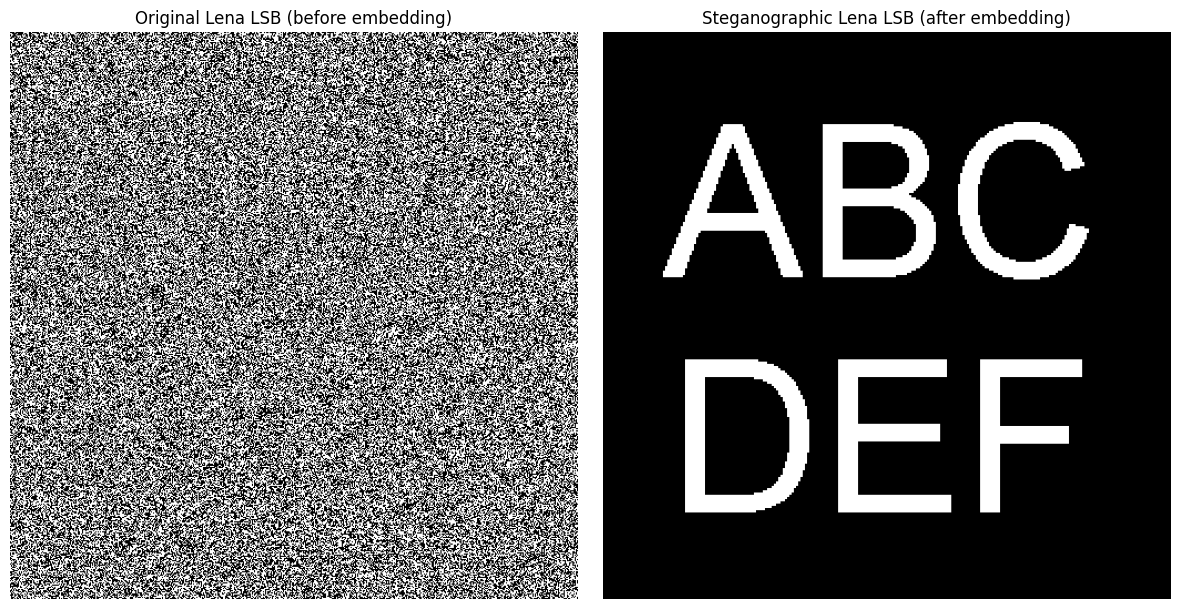

Comparison of LSBs: 131201 out of 262144 pixels have changed in the LSB.
This indicates the extent of the watermark embedding.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np


    original_lena_lsb = (gray_img & 1)

    stego_lena_lsb = (stego_img & 1) * 255

    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(original_lena_lsb, cmap='gray')
    plt.title('Original Lena LSB (before embedding)')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(stego_lena_lsb, cmap='gray')
    plt.title('Steganographic Lena LSB (after embedding)')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

    diff_pixels_lsb = np.sum(original_lena_lsb != stego_lena_lsb)
    total_pixels_lsb = original_lena_lsb.size
